In [1]:
import pickle
import json
import torch
import pandas as pd
import os

from post_analysis import *

/opt/anaconda3/envs/firegnn/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def load_pickle(filepath):
    with open(filepath, 'rb') as f:
        obj = pickle.load(f)
    return obj

def load_json(filepath):
    with open(filepath, 'rb') as f:
        obj = json.load(f)
    return obj

In [3]:
result_path = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/GAT/results.pkl"
rule_path = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/GAT/cv_fuzzy_rules.pkl"
param_path = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/GAT/cv_fuzzy_params.pkl"
meta_path = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/graph_meta.json"

result = load_pickle(result_path)
fuzzy_rule = load_pickle(rule_path)
fuzzy_params = load_pickle(param_path) 
meta = load_json(meta_path)

In [4]:
result['FuzzyGAT_direct_rules']['fuzzy_rules'][0].size()

torch.Size([691, 185])

In [5]:
result['FuzzyGAT_direct_rules']['fuzzy_params'][0]['theta'].size()

torch.Size([185])

In [6]:
patients = meta['patients']
rule_names = meta['rule_names']
direct_names = meta['direct_rule_names']
topo_names = ['degrees', 'clustering', 'eigenvector_centrality', 'degree_centrality', 'avg_edge_weight']

In [7]:
def parse_rule_activations(result_path:str, meta_path)->pd.DataFrame:
    # load result and meta
    with open(result_path, 'rb') as f:
        result = pickle.load(f)
    with open(meta_path, 'rb') as f:
        meta = json.load(f)
    
    patients = meta['patients']
    rule_names = meta['rule_names']
    direct_names = meta['direct_rule_names']
    topo_names = ['degrees', 'clustering', 'eigenvector_centrality', 'degree_centrality', 'avg_edge_weight']
    
    # extract rule_activations for all samples of all folds in one backbone model 
    rule_dfs = []
    for model_type, res in result.items():
        
        res_rules = res.get('fuzzy_rules')
        res_params = res.get('fuzzy_params')
        if isinstance(res_rules, list) and len(res_rules) !=0:
            for fold_idx, rules in enumerate(res_rules):
                if rules is None: # or not isinstance(rules, torch.Tensor):
                    continue
                
                # get rule activations 
                num_rules = rules.size(1)
                # print(rules.size())
                df = pd.DataFrame(rules)
                if num_rules == 5:
                    df.columns = topo_names
                elif num_rules == 185:
                    df.columns = direct_names
                elif num_rules == 190:
                    df.columns = topo_names + direct_names
                elif num_rules == 741:
                    df.columns = rule_names
                else:
                    df.columns = topo_names + rule_names
                df.insert(loc=0, column='sample_id', value=patients)
                df.insert(loc=1, column='model', value=model_type)
                df.insert(loc=2,column='fold',value=fold_idx+1)
            
                rule_dfs.append(df)

    df_rule_activation = pd.concat(rule_dfs, axis=0)
    return df_rule_activation

In [8]:
# parse root folder to get all rule actiavtion for all backbone models
def parse_all_rule_activations(root_dir:str, output_dir:Optional[str]=None):
    activation_dfs = []
    for dirpath, _, filenames in os.walk(root_dir):
        
        # root_dir/dataset/k/backbone/results.pkl
        if 'results.pkl' not in filenames:
            continue
        result_path = os.path.join(dirpath,'results.pkl')

        # Calculate meta_path by going exactly one directory up from 'backbone' to 'k'
        parent_dir = os.path.dirname(dirpath)
        meta_path = os.path.join(parent_dir, 'graph_meta.json')
        
        # Safety check to ensure the meta file actually exists before processing
        if not os.path.exists(meta_path):
            print(f"Warning: Missing graph_meta.json for {result_path}. Skipping.")
            continue

        rel=os.path.relpath(dirpath, root_dir)
        parts = rel.split(os.sep)

        if len(parts) < 3:
            continue
        dataset=parts[0]
        k=parts[1]
        backbone=parts[2]

        df = parse_rule_activations(result_path, meta_path)
        df.insert(loc=3, column='dataset', value=dataset)
        df.insert(loc=4, column='k', value=k)
        df.insert(loc=5,column='backbone',value=backbone)
        activation_dfs.append(df)
    
    # Combine everything
    if activation_dfs:
        df_rule_activation = pd.concat(activation_dfs, axis=0, ignore_index=True)
    else:
        print("No valid result files found.")
        return pd.DataFrame()
        
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        df_rule_activation.to_csv(os.path.join(output_dir, 'df_samplewise_rule_activations.csv'))
    
    return df_rule_activation

In [9]:
root_dir= "../nesy_gnn/results/explain/AD_KG"
output_dir = "../nesy_gnn/results/explain/AD_KG/rules"
df_all_activation = parse_all_rule_activations(root_dir, output_dir)

df_all_activation

,sample_id,model,fold,dataset,k,backbone,degrees,clustering,eigenvector_centrality,degree_centrality,...,chain_ACTB_5hops_AD,chain_GPS1_4hops_AD,chain_GPS1_5hops_CTL,chain_GPS1_5hops_AD,chain_GUSB_4hops_AD,chain_GUSB_5hops_CTL,chain_GUSB_5hops_AD,chain_PPP1CA_4hops_AD,chain_PPP1CA_5hops_CTL,chain_PPP1CA_5hops_AD
0,DCR00001_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,0.443283,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DCR00004_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,0.552419,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DCR00009_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.612887,0.518729,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,DCR00013_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,0.511766,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DCR00014_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.852141,0.923173,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69095,TLSMCI607_1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.332155,0.960963,0.419785,0.329545,...,0.683675,0.684229,0.682762,0.686348,0.686427,0.685961,0.724487,0.725035,0.725473,0.581494
69096,TLSMCI608_1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.578092,0.828952,0.419785,0.580268,...,0.747017,0.747404,0.746337,0.839109,0.839582,0.838211,0.752516,0.753009,0.753426,0.833568
69097,TLSMCI609_1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.410801,0.621224,0.432282,0.409620,...,0.262853,0.263923,0.261337,0.271425,0.270232,0.273024,0.356357,0.357228,0.357609,0.236438
69098,TLSMCI611_1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.935808,0.351296,0.646809,0.939164,...,0.264917,0.265989,0.263397,0.303512,0.302356,0.305036,0.282792,0.283609,0.283923,0.320413


In [10]:
# load df_ig_attributions
df_attributions = pd.read_csv("../nesy_gnn/results/explain/AD_KG/rules/df_samplewise_rule_attributions.csv", index_col=0)
df_attributions = df_attributions.reset_index()
df_attributions

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_3157/1993854254.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_attributions = df_attributions.reset_index()


,sample_id,Label,Prediction,gate,fold,model,dataset,k,backbone,degrees,...,chain_ACTB_5hops_AD,chain_GPS1_4hops_AD,chain_GPS1_5hops_CTL,chain_GPS1_5hops_AD,chain_GUSB_4hops_AD,chain_GUSB_5hops_CTL,chain_GUSB_5hops_AD,chain_PPP1CA_4hops_AD,chain_PPP1CA_5hops_CTL,chain_PPP1CA_5hops_AD
0,DCR00001_1,1,1,0.508388,1,FuzzyGAT_topo,ANMerge,4,GAT,-0.000098,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DCR00004_1,1,1,0.484337,1,FuzzyGAT_topo,ANMerge,4,GAT,0.000030,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DCR00009_1,0,1,0.458731,1,FuzzyGAT_topo,ANMerge,4,GAT,-0.000094,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,DCR00013_1,0,1,0.500154,1,FuzzyGAT_topo,ANMerge,4,GAT,-0.000108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DCR00014_1,0,0,0.476903,1,FuzzyGAT_topo,ANMerge,4,GAT,0.000111,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69095,TLSMCI607_1,1,1,0.702342,5,FuzzyGIN_topo_all_rules,ANMerge,4,GIN,-0.001858,...,0.001489,0.003278,0.001061,0.002879,0.001547,0.002417,-0.001478,-0.000923,-0.000168,-0.000324
69096,TLSMCI608_1,1,1,0.712895,5,FuzzyGIN_topo_all_rules,ANMerge,4,GIN,0.000887,...,0.002209,0.001674,0.000589,0.001162,0.000988,0.001966,-0.001192,-0.001491,0.000144,-0.000661
69097,TLSMCI609_1,1,1,0.657470,5,FuzzyGIN_topo_all_rules,ANMerge,4,GIN,-0.000961,...,-0.002652,-0.002672,-0.000680,-0.001832,-0.001389,-0.002235,0.001510,0.001049,0.000559,0.000326
69098,TLSMCI611_1,1,0,0.676286,5,FuzzyGIN_topo_all_rules,ANMerge,4,GIN,-0.002036,...,0.000389,0.000244,0.000341,-0.000536,-0.000438,0.000773,-0.001326,0.000792,-0.000058,0.000886


In [11]:
df_all_activation.insert(loc=1, column='Label', value = df_attributions['Label'])
df_all_activation.insert(loc=2, column='Prediction', value=df_attributions['Prediction'])
df_all_activation

,sample_id,Label,Prediction,model,fold,dataset,k,backbone,degrees,clustering,...,chain_ACTB_5hops_AD,chain_GPS1_4hops_AD,chain_GPS1_5hops_CTL,chain_GPS1_5hops_AD,chain_GUSB_4hops_AD,chain_GUSB_5hops_CTL,chain_GUSB_5hops_AD,chain_PPP1CA_4hops_AD,chain_PPP1CA_5hops_CTL,chain_PPP1CA_5hops_AD
0,DCR00001_1,1,1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DCR00004_1,1,1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DCR00009_1,0,1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.612887,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,DCR00013_1,0,1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DCR00014_1,0,0,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.852141,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69095,TLSMCI607_1,1,1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.332155,0.960963,...,0.683675,0.684229,0.682762,0.686348,0.686427,0.685961,0.724487,0.725035,0.725473,0.581494
69096,TLSMCI608_1,1,1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.578092,0.828952,...,0.747017,0.747404,0.746337,0.839109,0.839582,0.838211,0.752516,0.753009,0.753426,0.833568
69097,TLSMCI609_1,1,1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.410801,0.621224,...,0.262853,0.263923,0.261337,0.271425,0.270232,0.273024,0.356357,0.357228,0.357609,0.236438
69098,TLSMCI611_1,1,0,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.935808,0.351296,...,0.264917,0.265989,0.263397,0.303512,0.302356,0.305036,0.282792,0.283609,0.283923,0.320413


In [12]:
from typing import Optional
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_rule_importance(df: pd.DataFrame, x_col: str, y_col: str, 
                         title: Optional[str] = None,
                         cmap='coolwarm',
                         central_vertical_line:float=0.0,
                         interpolate: bool = True, 
                         save_path: Optional[str] = None) -> pd.DataFrame:
    """
    Plots a SHAP-style summary scatter plot of rule importances.

    Args:
        df (pd.DataFrame): The dataframe containing the attribution values.
        x_col (str): The column name representing the X-axis (Importance values).
        y_col (str): The column name representing the Y-axis (e.g., 'rule_name').
        title (Optional[str]): Custom title for the plot. Defaults to None.
        interpolate (bool): If True, simulates more data points by duplicating 
                            rows and adding Gaussian noise. Defaults to True.
        save_path (Optional[str]): If provided, saves the figure to this file path.

    Returns:
        pd.DataFrame: A copy of the processed dataframe with calculated y-positions.
    """
    plot_df = df.copy()
    color_col = x_col

    if interpolate:
        # 1. Duplicate and add noise to simulate having multiple points per rule
        plot_df = pd.concat([plot_df] * 20, ignore_index=True)
        plot_df[x_col] += np.random.normal(0, 0.001, len(plot_df))

    # 2. Sort rules by their mean importance so the most important is at the top
    # Double brackets [[x_col]] and by=x_col safely prevents DataFrame sorting errors
    mean_importance = plot_df.groupby(y_col)[[x_col]].mean()
    order = mean_importance.sort_values(by=x_col, ascending=False).index
    
    y_mapping = {rule: i for i, rule in enumerate(order)}
    plot_df['y_pos'] = plot_df[y_col].map(y_mapping)
    
    # print top-5 importance rules names
    top_rules = order[:5].tolist()
    print(f"Top-5 {y_col} by {x_col}:\n{top_rules}")

    # 3. Create the plot
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Add a slight vertical jitter so points don't heavily overlap
    jitter = np.random.normal(0, 0.05, size=len(plot_df))

    # Scatter plot using a colormap
    sc = ax.scatter(
        plot_df[x_col], 
        plot_df['y_pos'] + jitter, 
        c=plot_df[color_col], 
        cmap=cmap, # blue-pink-red
        s=15, 
        alpha=0.8,
        edgecolors='none'
    )

    # 4. Formatting
    # Set Y-axis labels to the rule names
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=8)
    ax.invert_yaxis() # Puts the most important rule at the top

    # Add the central vertical line at 0
    ax.axvline(central_vertical_line, color='grey', linestyle='-', linewidth=1.5, alpha=0.5)

    # Style the axes
    ax.set_xlabel(x_col, fontsize=12)
    if title:
        ax.set_title(title, fontsize=14, pad=15)
        
    ax.xaxis.grid(True, linestyle='--', alpha=0.3)
    sns.despine(left=True, bottom=False)
    ax.tick_params(axis='y', length=0) # Remove y-axis tick marks for a cleaner look

    # 5. Add and format the colorbar
    cbar = plt.colorbar(sc, ax=ax, aspect=40, pad=0.05)
    cbar.set_label('Feature Value', fontsize=10)
    cbar.set_ticks([plot_df[color_col].min(), plot_df[color_col].max()])
    cbar.set_ticklabels(['Low', 'High'])
    cbar.ax.set_frame_on(False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved plot to {save_path}")
    plt.show()

    return plot_df

Top-5 rule_name by DCR00001_1:
['direct_TNFRSF1B_CTL', 'chain_MMP9_APP_CTL', 'chain_FOXO4_insulin receptor sig_CTL', 'chain_SNCA_MAPT_AD', 'direct_IRS2_CTL']


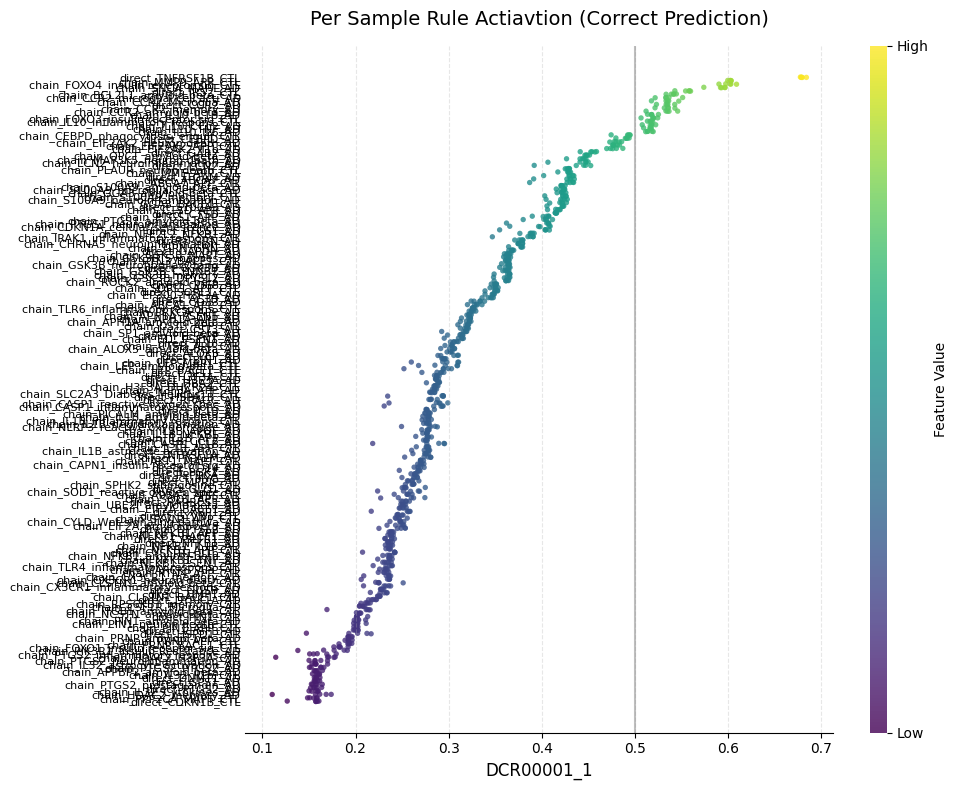

Top-5 rule_name by DCR00009_1:
['chain_IL10_CCL2_AD', 'chain_IL10_inflammatory respons_CTL', 'chain_IL10_IL1B_AD', 'chain_IL10_IL6_AD', 'chain_IL10_TNF_AD']


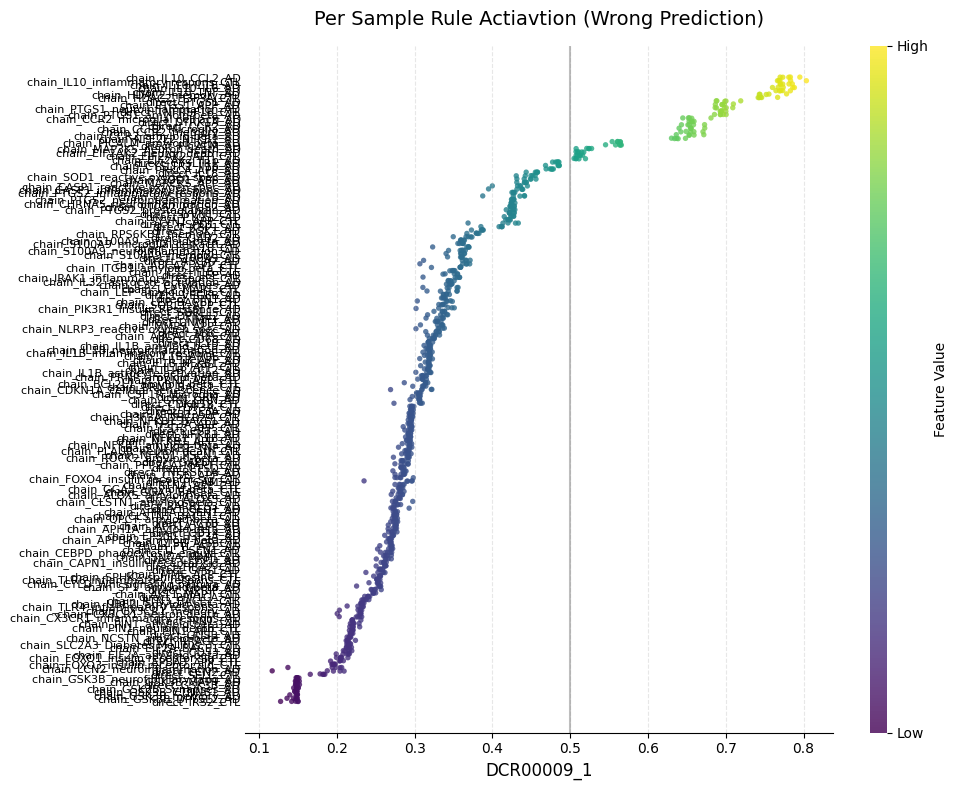

In [19]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"

plot_df = df_all_activation[(df_all_activation['model']==model_type) &
                            (df_all_activation['dataset']==dataset) &
                            (df_all_activation['k'] == str(k))
                            ]

if 'sample_id' not in plot_df.columns and plot_df.index.name=='sample_id':
    plot_df.reset_index()
non_rule_cols = ['model', 'fold', 'dataset', 'k', 'backbone', 'Label', 'Prediction']
rule_cols = [col for col in plot_df.columns if col not in non_rule_cols]

plot_df = plot_df[rule_cols]

# melt
melted = plot_df.melt(id_vars='sample_id', var_name='rule_name', value_name='activation')
melted['occ'] = melted.groupby(['sample_id', 'rule_name']).cumcount()

new_df = melted.pivot(index=['rule_name','occ'], columns='sample_id', values='activation').reset_index()
new_df = new_df.drop(columns=['occ']).dropna()

df_plot1 = plot_rule_importance(df=new_df,
                            x_col='DCR00001_1',
                            y_col='rule_name',
                            title='Per Sample Rule Actiavtion (Correct Prediction)',
                            cmap='viridis',
                            central_vertical_line=0.5,
                            interpolate=False,
                            save_path = False)

df_plot2 = plot_rule_importance(df=new_df,
                            x_col='DCR00009_1',
                            y_col='rule_name',
                            title='Per Sample Rule Actiavtion (Wrong Prediction)',
                            cmap='viridis',
                            central_vertical_line=0.5,
                            interpolate=False,
                            save_path = False)

Top-5 rule_name by DCR00013_1:
['direct_TNFRSF1B_CTL', 'chain_CX3CR1_memory_AD', 'chain_CX3CR1_neuron death_AD', 'chain_CX3CR1_inflammatory respons_AD', 'chain_CCR2_microglial cell acti_AD']


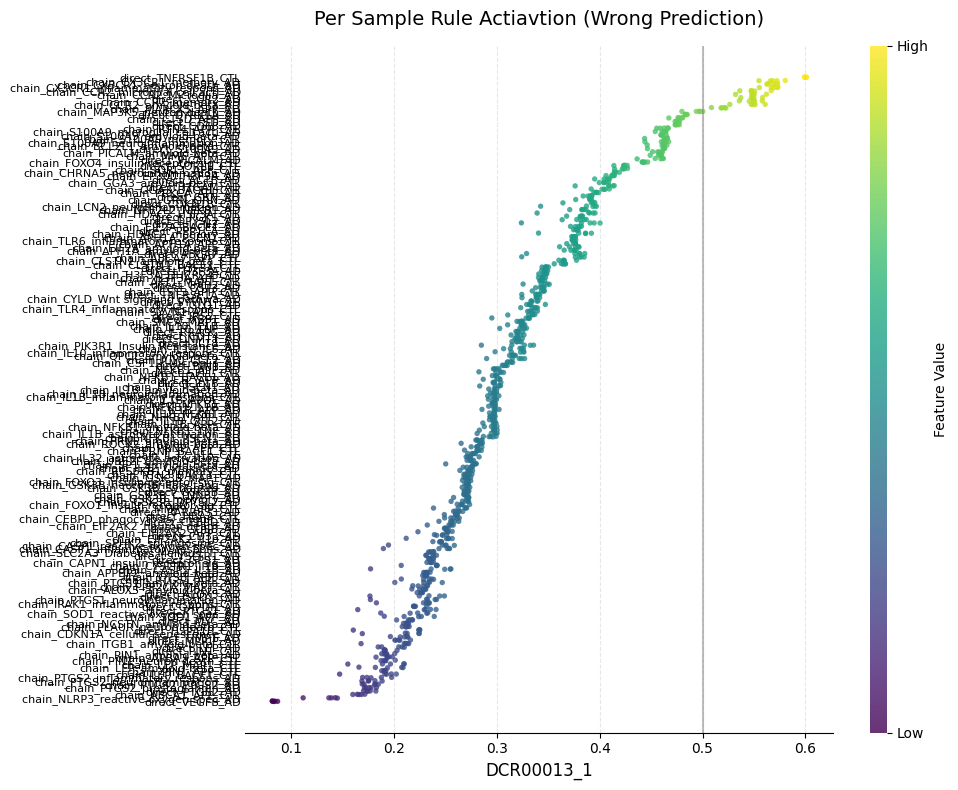

In [22]:
df_plot2 = plot_rule_importance(df=new_df,
                            x_col='DCR00013_1',
                            y_col='rule_name',
                            title='Per Sample Rule Actiavtion (Wrong Prediction)',
                            cmap='viridis',
                            central_vertical_line=0.5,
                            interpolate=False,
                            save_path = False)

In [20]:
df_sample1 = df_plot1[df_plot1['DCR00001_1']>0.5]
df_sample1 = df_sample1.sort_values(by='DCR00001_1', ascending=False)
df_sample1['rule_name'].unique()

<StringArray>
[                 'direct_TNFRSF1B_CTL',
 'chain_FOXO4_insulin receptor sig_CTL',
                   'chain_MMP9_APP_CTL',
                   'chain_SNCA_MAPT_AD',
                      'direct_IRS2_CTL',
   'chain_CCR2_microglial cell acti_AD',
              'chain_CCR2_Microglia_AD',
           'chain_CCR2_amyloid-beta_AD',
        'chain_BCL2L1_amyloid-beta_CTL',
                 'chain_CCR2_memory_AD',
                       'direct_CCR2_AD',
                   'chain_IL10_IL1B_AD',
 'chain_FOXO3_insulin receptor sig_CTL',
                   'chain_IL10_CCL2_AD',
                    'chain_IL10_IL6_AD',
  'chain_IL10_inflammatory respons_CTL',
                    'chain_IL10_TNF_AD']
Length: 17, dtype: str

In [24]:
df_sample2 = df_plot2[df_plot2['DCR00013_1']>0.5]
df_sample2 = df_sample2.sort_values(by='DCR00013_1', ascending=False)
df_sample2['rule_name'].unique()

<StringArray>
[                 'direct_TNFRSF1B_CTL',
               'chain_CX3CR1_memory_AD',
 'chain_CX3CR1_inflammatory respons_AD',
         'chain_CX3CR1_neuron death_AD',
   'chain_CCR2_microglial cell acti_AD',
              'chain_CCR2_Microglia_AD',
           'chain_CCR2_amyloid-beta_AD',
                       'direct_CCR2_AD',
                 'chain_CCR2_memory_AD',
                  'chain_MARCKS_APP_AD',
         'chain_MAP3K5_neuron death_AD']
Length: 11, dtype: str

## Correctly vs. Wrongsly Predicted Rule Activations

Top-5 rule_name by mean_activation_score:
['chain_EIF2AK2_neuron death_AD', 'chain_EIF2AK2_APP_CTL', 'chain_EIF2AK2_Il1b_AD', 'chain_PLAUR_neuron death_CTL', 'direct_HSPA1B_CTL']


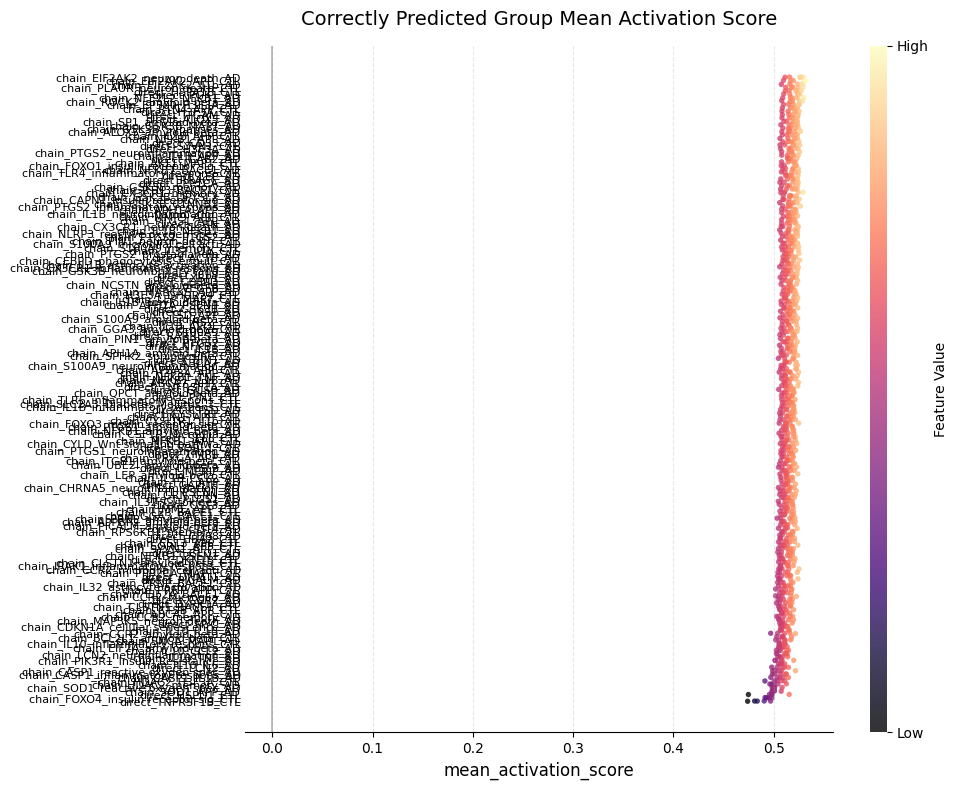

Top-5 rule_name by mean_activation_score:
['direct_TNFRSF1B_CTL', 'chain_FOXO4_insulin receptor sig_CTL', 'chain_CCR2_microglial cell acti_AD', 'chain_CCR2_Microglia_AD', 'direct_CCR2_AD']


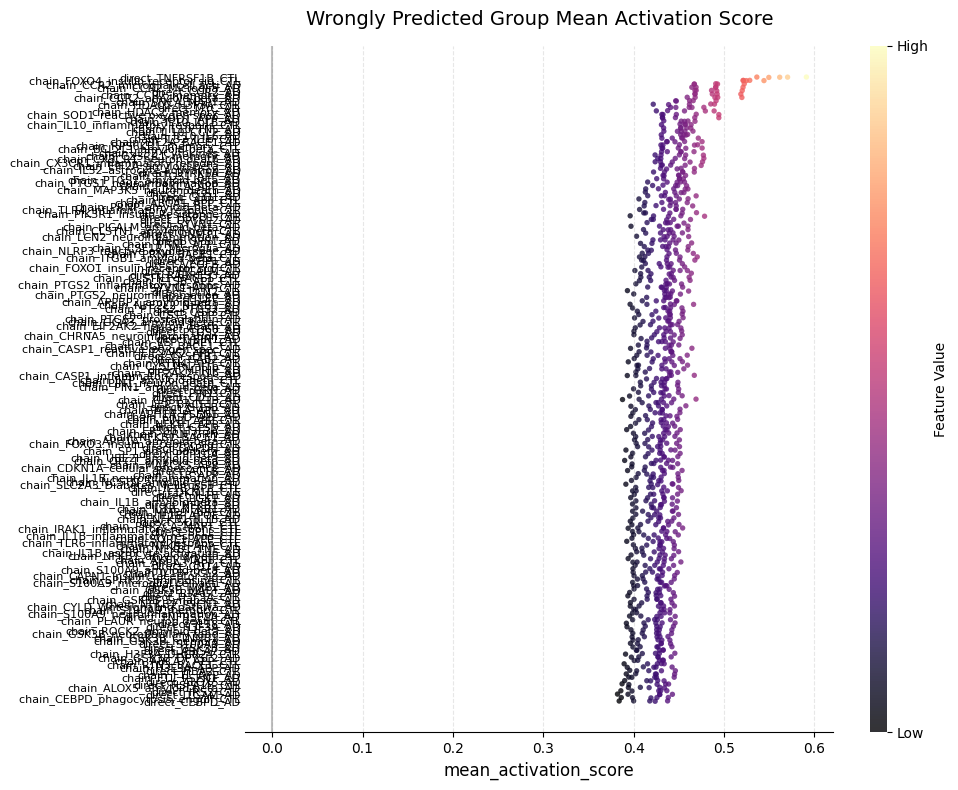

,dataset,k,model,fold,rule_name,mean_activation_score,y_pos
505,ANMerge,4,FuzzyGAT_direct_rules,1,chain_SORL1_APP_CTL,0.427295,136
506,ANMerge,4,FuzzyGAT_direct_rules,2,chain_SORL1_APP_CTL,0.436704,136
507,ANMerge,4,FuzzyGAT_direct_rules,3,chain_SORL1_APP_CTL,0.398140,136
508,ANMerge,4,FuzzyGAT_direct_rules,4,chain_SORL1_APP_CTL,0.440019,136
509,ANMerge,4,FuzzyGAT_direct_rules,5,chain_SORL1_APP_CTL,0.416292,136
...,...,...,...,...,...,...,...
18905,ANMerge,4,FuzzyGAT_direct_rules,1,chain_GRN_GRN_AD,0.433229,105
18906,ANMerge,4,FuzzyGAT_direct_rules,2,chain_GRN_GRN_AD,0.438838,105
18907,ANMerge,4,FuzzyGAT_direct_rules,3,chain_GRN_GRN_AD,0.399824,105
18908,ANMerge,4,FuzzyGAT_direct_rules,4,chain_GRN_GRN_AD,0.448092,105


In [17]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"

plot_wrong_correct_mean_rulescore(df_samples=df_all_activation, 
                                        dataset=dataset, 
                                        model_type=model_type, 
                                        k=k,
                                        rule_value_name='mean_activation_score',
                                        plot_correct=True,
                                        cmap='magma',
                                        save_path=None)

plot_wrong_correct_mean_rulescore(df_samples=df_all_activation, 
                                        dataset=dataset, 
                                        model_type=model_type, 
                                        k=k,
                                        rule_value_name='mean_activation_score',
                                        plot_correct=False,
                                        cmap='magma',
                                        save_path=None)

## Correctly Predicted Disease vs.Control Group Rule Activations

Top-5 rule_name by mean_activation_score:
['direct_ITGAM_AD', 'direct_GAB2_AD', 'chain_EIF2AK2_APP_CTL', 'chain_EIF2AK2_neuron death_AD', 'chain_EIF2AK2_Il1b_AD']


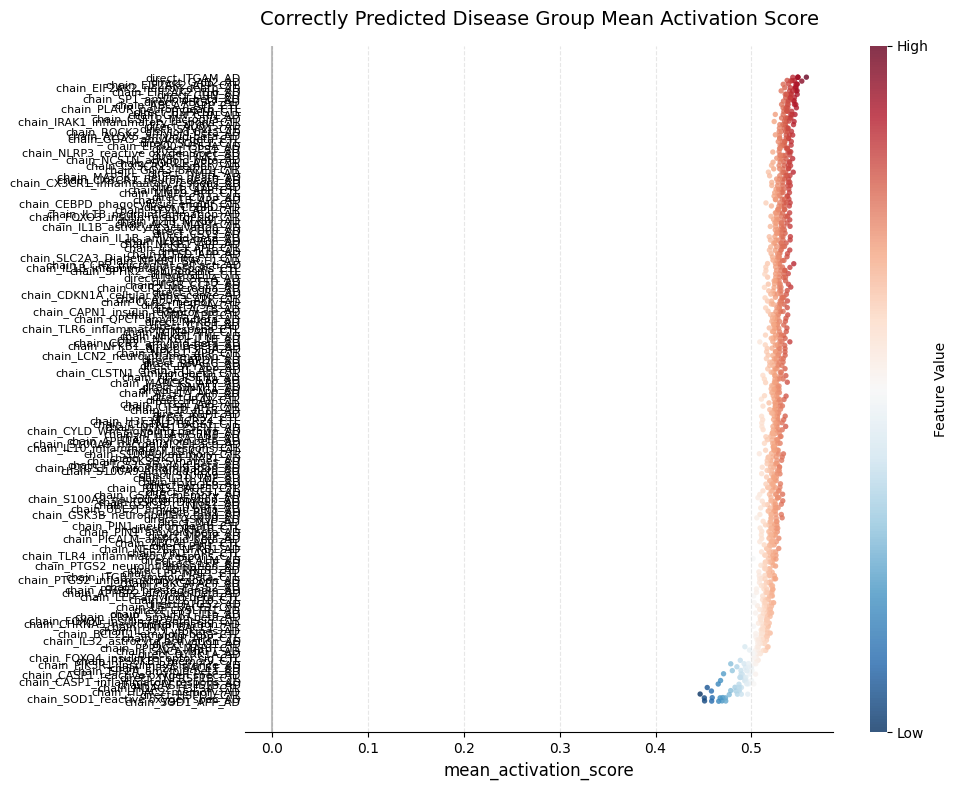

Top-5 rule_name by mean_activation_score:
['chain_SOD1_reactive oxygen spec_AD', 'chain_SOD1_APP_AD', 'chain_HDAC2_memory_AD', 'chain_HDAC2_H3F3A_CTL', 'chain_EIF2A_BACE1_AD']


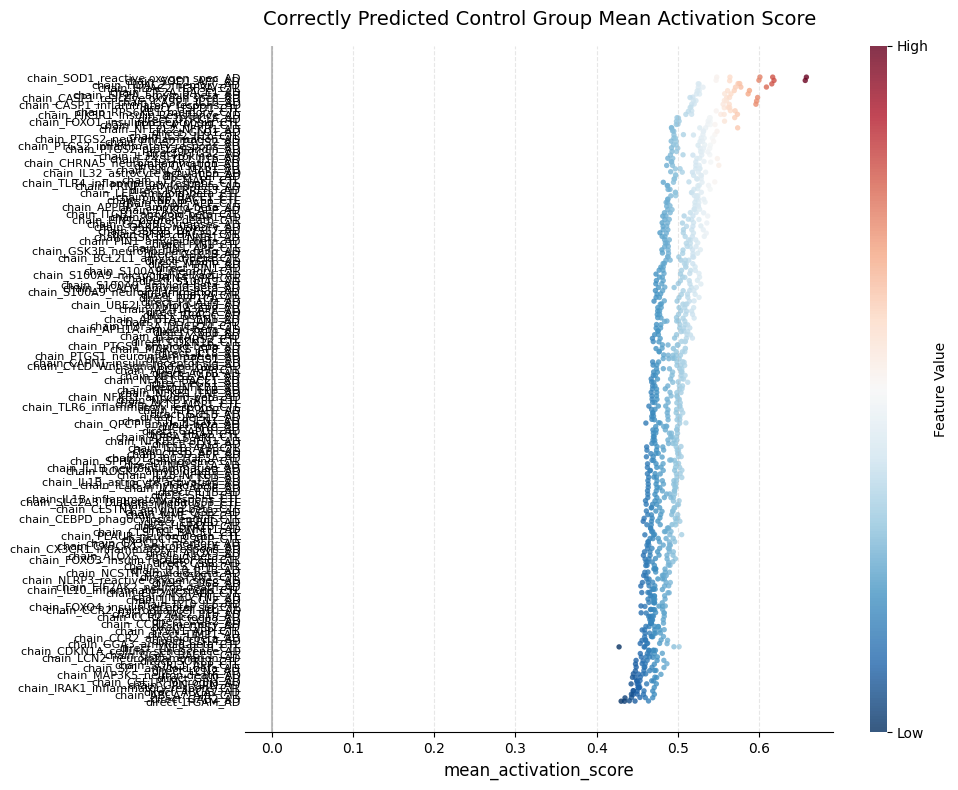

,dataset,k,model,fold,rule_name,mean_activation_score,y_pos
485,ANMerge,4,FuzzyGAT_direct_rules,1,chain_SORL1_APP_CTL,0.447943,173
486,ANMerge,4,FuzzyGAT_direct_rules,2,chain_SORL1_APP_CTL,0.456177,173
487,ANMerge,4,FuzzyGAT_direct_rules,3,chain_SORL1_APP_CTL,0.486694,173
488,ANMerge,4,FuzzyGAT_direct_rules,4,chain_SORL1_APP_CTL,0.459981,173
489,ANMerge,4,FuzzyGAT_direct_rules,5,chain_SORL1_APP_CTL,0.471193,173
...,...,...,...,...,...,...,...
18149,ANMerge,4,FuzzyGAT_direct_rules,1,chain_GRN_GRN_AD,0.442571,179
18150,ANMerge,4,FuzzyGAT_direct_rules,2,chain_GRN_GRN_AD,0.450009,179
18151,ANMerge,4,FuzzyGAT_direct_rules,3,chain_GRN_GRN_AD,0.473696,179
18152,ANMerge,4,FuzzyGAT_direct_rules,4,chain_GRN_GRN_AD,0.452006,179


In [18]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"

plot_disease_control_mean_rulescore(df_all_activation, 
                                        dataset, 
                                        model_type, 
                                        k,
                                        rule_value_name='mean_activation_score',
                                        plot_disease=True,
                                        cmap='RdBu_r',
                                        save_path=None)

plot_disease_control_mean_rulescore(df_all_activation, 
                                        dataset, 
                                        model_type, 
                                        k,
                                        rule_value_name='mean_activation_score',
                                        plot_disease=False,
                                        cmap='RdBu_r',
                                        save_path=None)  